In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
cwd = Path.cwd()
PROJECT_DIR = cwd if (cwd / "data").exists() else cwd.parent

DATA_PATH = PROJECT_DIR / "data" / "ola_rides_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (103024, 24)


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Booking_Hour,Ride_Time_Category,Booking_Day,Day_Name,Booking_Month
0,2024-07-26,13:59:59,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,13,Afternoon,26,Friday,July
1,2024-07-25,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,22,Night,25,Thursday,July
2,2024-07-30,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,19,Evening,30,Tuesday,July
3,2024-07-22,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,3,Night,22,Monday,July
4,2024-07-02,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,9,Morning,2,Tuesday,July


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Columns:
['Date', 'Time', 'Booking_ID', 'Booking_Status', 'Customer_ID', 'Vehicle_Type', 'Pickup_Location', 'Drop_Location', 'V_TAT', 'C_TAT', 'Canceled_Rides_by_Customer', 'Canceled_Rides_by_Driver', 'Incomplete_Rides', 'Incomplete_Rides_Reason', 'Booking_Value', 'Payment_Method', 'Ride_Distance', 'Driver_Ratings', 'Customer_Rating', 'Booking_Hour', 'Ride_Time_Category', 'Booking_Day', 'Day_Name', 'Booking_Month']

Data types:
Date                              str
Time                              str
Booking_ID                        str
Booking_Status                    str
Customer_ID                       str
Vehicle_Type                      str
Pickup_Location                   str
Drop_Location                     str
V_TAT                         float64
C_TAT                         float64
Canceled_Rides_by_Customer        str
Canceled_Rides_by_Driver          str
Incomplete_Rides                  str
Incomplete_Rides_Reason           str
Booking_Value                   int6

In [4]:
display(df.describe())

,V_TAT,C_TAT,Booking_Value,Ride_Distance,Driver_Ratings,Customer_Rating,Booking_Hour,Booking_Day
count,63967.000000,63967.000000,103024.000000,103024.000000,63967.000000,63967.000000,103024.000000,103024.000000
mean,170.876952,84.873372,548.751883,14.189927,3.997457,3.998313,11.479568,15.981267
std,80.803640,36.005100,536.541221,15.776270,0.576834,0.578957,6.911259,8.931225
min,35.000000,25.000000,100.000000,0.000000,3.000000,3.000000,0.000000,1.000000
25%,98.000000,55.000000,242.000000,0.000000,3.500000,3.500000,6.000000,8.000000
50%,168.000000,85.000000,386.000000,8.000000,4.000000,4.000000,11.000000,16.000000
75%,238.000000,115.000000,621.000000,26.000000,4.500000,4.500000,17.000000,24.000000
max,308.000000,145.000000,2999.000000,49.000000,5.000000,5.000000,23.000000,31.000000


In [5]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))

C:\Users\Rinku Saroj\AppData\Local\Temp\ipykernel_28620\974036522.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns



--- Date ---
Date
2024-07-30    3432
2024-07-13    3409
2024-07-02    3388
2024-07-12    3382
2024-07-22    3377
2024-07-23    3377
2024-07-10    3375
2024-07-16    3371
2024-07-29    3370
2024-07-27    3362
Name: count, dtype: int64

--- Time ---
Time
00:53:00    101
22:12:00     97
01:12:59     96
18:20:00     95
08:30:59     95
09:29:00     95
14:33:59     95
20:03:00     94
10:00:00     93
11:05:00     93
Name: count, dtype: int64

--- Booking_ID ---
Booking_ID
CNR7153255142    1
CNR2940424040    1
CNR2982357879    1
CNR2395710036    1
CNR1797421769    1
CNR8787177882    1
CNR3612067560    1
CNR5374902489    1
CNR5030602354    1
CNR6328453219    1
Name: count, dtype: int64

--- Booking_Status ---
Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64

--- Customer_ID ---
Customer_ID
CID954071    5
CID268274    4
CID539191    4
CID189965    4
CID952434    4
CID329193    4
CID38

In [6]:
booking_status = df['Booking_Status'].value_counts()

booking_percentage = (
    df['Booking_Status'].value_counts(normalize=True) * 100
)

status_summary = pd.DataFrame({
    'Bookings': booking_status,
    'Percentage': booking_percentage.round(2)
})

display(status_summary)

,Bookings,Percentage
Booking_Status,,
Success,63967,62.09
Canceled by Driver,18434,17.89
Canceled by Customer,10499,10.19
Driver Not Found,10124,9.83


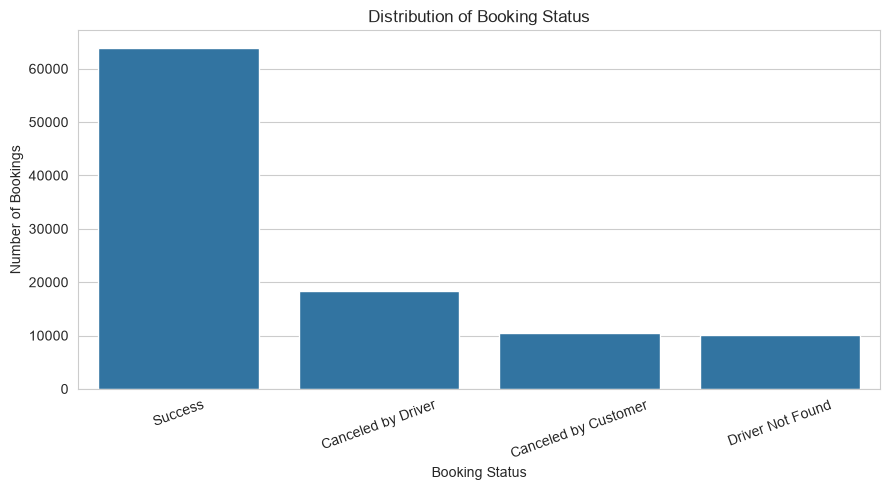

In [7]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Booking_Status',
    order=df['Booking_Status'].value_counts().index
)

plt.title('Distribution of Booking Status')
plt.xlabel('Booking Status')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [8]:
vehicle_bookings = df['Vehicle_Type'].value_counts()

display(vehicle_bookings)

Vehicle_Type
Prime Sedan    14877
eBike          14816
Auto           14755
Prime Plus     14707
Bike           14662
Prime SUV      14655
Mini           14552
Name: count, dtype: int64

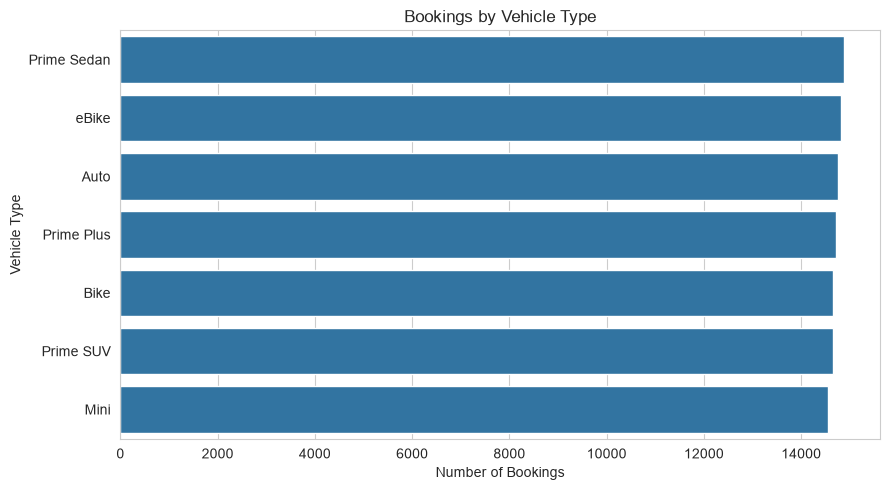

In [9]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    y='Vehicle_Type',
    order=vehicle_bookings.index
)

plt.title('Bookings by Vehicle Type')
plt.xlabel('Number of Bookings')
plt.ylabel('Vehicle Type')
plt.tight_layout()
plt.show()

In [10]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

daily_bookings = df.groupby('Date').size()

display(daily_bookings.head())

Date
2024-07-01    3351
2024-07-02    3388
2024-07-03    3358
2024-07-04    3274
2024-07-05    3306
dtype: int64

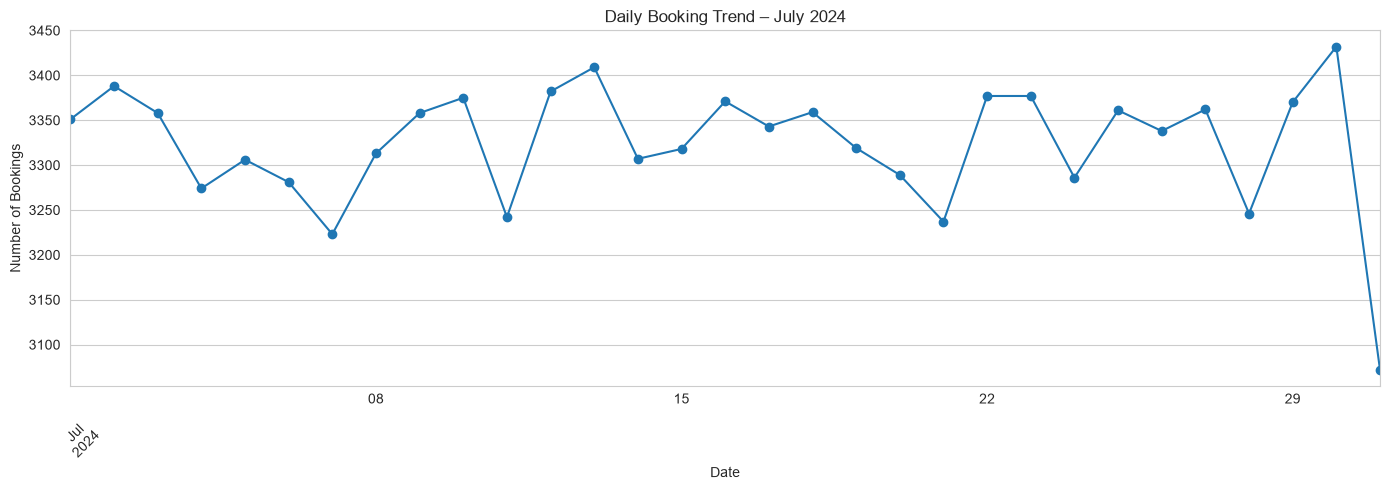

In [11]:
plt.figure(figsize=(14, 5))

daily_bookings.plot(kind='line', marker='o')

plt.title('Daily Booking Trend – July 2024')
plt.xlabel('Date')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
hourly_bookings = df['Booking_Hour'].value_counts().sort_index()

display(hourly_bookings)

Booking_Hour
0     4318
1     4392
2     4242
3     4201
4     4330
5     4197
6     4271
7     4388
8     4290
9     4347
10    4409
11    4197
12    4408
13    4363
14    4154
15    4376
16    4344
17    4270
18    4176
19    4356
20    4143
21    4343
22    4362
23    4147
Name: count, dtype: int64

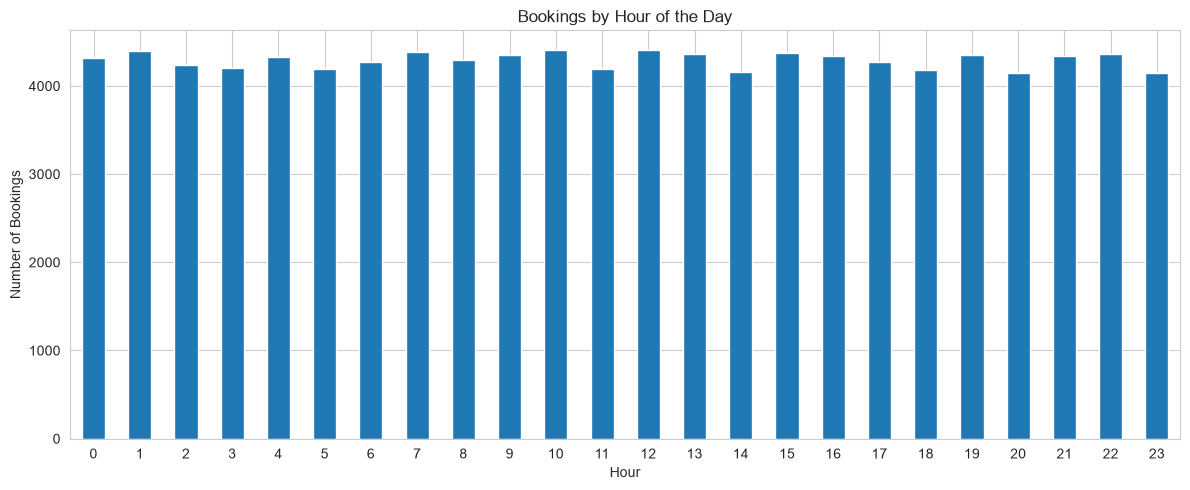

In [13]:
plt.figure(figsize=(12, 5))

hourly_bookings.plot(kind='bar')

plt.title('Bookings by Hour of the Day')
plt.xlabel('Hour')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
successful_df = df[df['Booking_Status'] == 'Success'].copy()

print("Successful Bookings:", len(successful_df))
print("Total Revenue: ₹", successful_df['Booking_Value'].sum())
print("Average Booking Value: ₹", round(
    successful_df['Booking_Value'].mean(), 2
))

Successful Bookings: 63967
Total Revenue: ₹ 35080467
Average Booking Value: ₹ 548.42


In [15]:
payment_revenue = (
    successful_df.groupby('Payment_Method')['Booking_Value']
    .sum()
    .sort_values(ascending=False)
)

display(payment_revenue)

Payment_Method
Cash           19260316
UPI            14168436
Credit Card     1312793
Debit Card       338922
Name: Booking_Value, dtype: int64

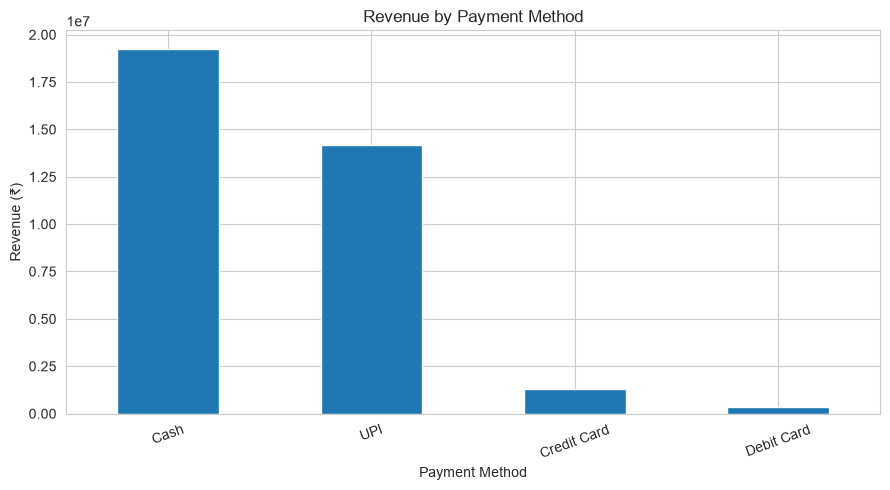

In [16]:
plt.figure(figsize=(9, 5))

payment_revenue.plot(kind='bar')

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [17]:
customer_cancel = df[
    df['Booking_Status'] == 'Canceled by Customer'
]

display(
    customer_cancel['Canceled_Rides_by_Customer']
    .value_counts()
)

Canceled_Rides_by_Customer
Driver is not moving towards pickup location    3175
Driver asked to cancel                          2670
Change of plans                                 2081
AC is Not working                               1568
Wrong Address                                   1005
Name: count, dtype: int64

In [18]:
driver_cancel = df[
    df['Booking_Status'] == 'Canceled by Driver'
]

display(
    driver_cancel['Canceled_Rides_by_Driver']
    .value_counts()
)

Canceled_Rides_by_Driver
Personal & Car related issue           6542
Customer related issue                 5413
Customer was coughing/sick             3654
More than permitted people in there    2825
Name: count, dtype: int64

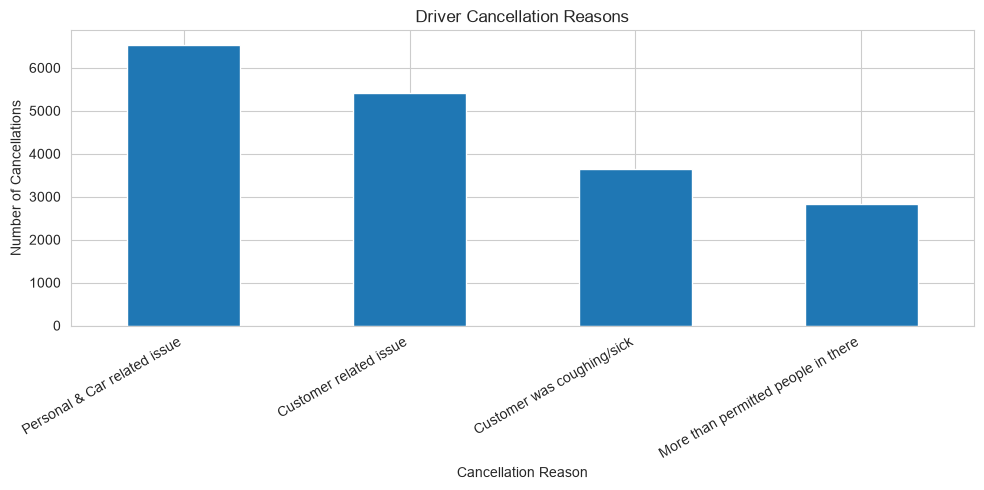

In [19]:
plt.figure(figsize=(10, 5))

driver_cancel['Canceled_Rides_by_Driver'].value_counts().plot(
    kind='bar'
)

plt.title('Driver Cancellation Reasons')
plt.xlabel('Cancellation Reason')
plt.ylabel('Number of Cancellations')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [20]:
rating_summary = df.groupby('Vehicle_Type').agg(
    Average_Driver_Rating=('Driver_Ratings', 'mean'),
    Average_Customer_Rating=('Customer_Rating', 'mean')
).round(2)

display(rating_summary)

,Average_Driver_Rating,Average_Customer_Rating
Vehicle_Type,,
Auto,4.00,4.00
Bike,3.98,3.99
Mini,3.99,4.00
Prime Plus,4.00,4.01
Prime SUV,4.01,4.00
Prime Sedan,3.99,4.00
eBike,4.01,3.99


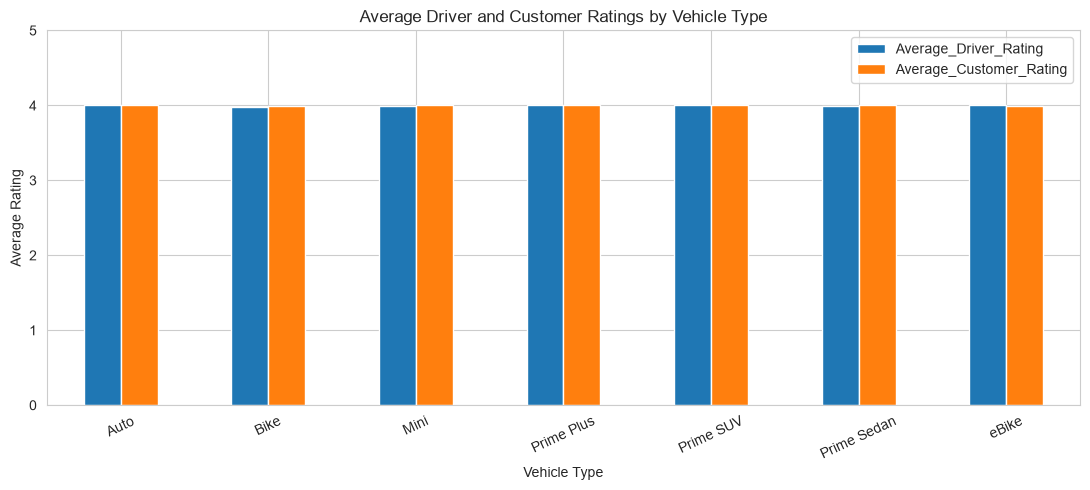

In [21]:
rating_summary.plot(
    kind='bar',
    figsize=(11, 5)
)

plt.title('Average Driver and Customer Ratings by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Rating')
plt.ylim(0, 5)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [22]:
print(df['Incomplete_Rides'].value_counts(dropna=False))

incomplete_df = df[df['Incomplete_Rides'] == 'Yes']

print("\nIncomplete ride reasons:")
display(
    incomplete_df['Incomplete_Rides_Reason'].value_counts()
)

Incomplete_Rides
No     60041
NaN    39057
Yes     3926
Name: count, dtype: int64

Incomplete ride reasons:


Incomplete_Rides_Reason
Customer Demand      1601
Vehicle Breakdown    1591
Other Issue           734
Name: count, dtype: int64

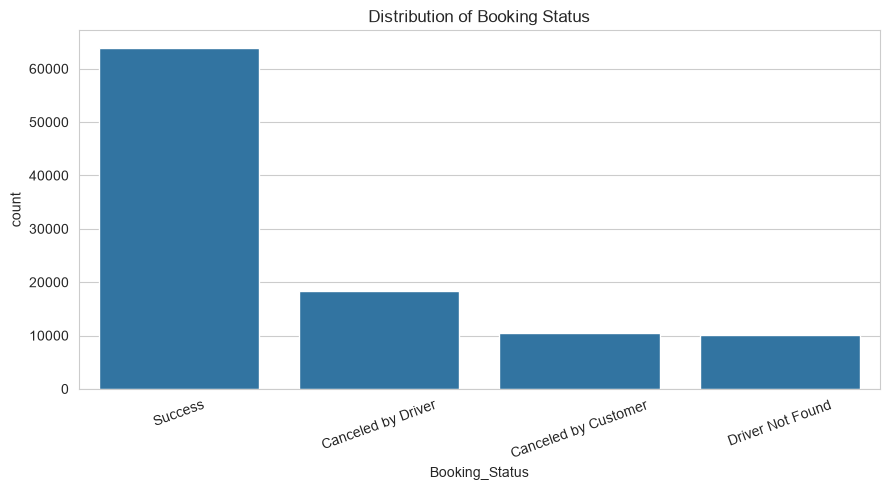

In [23]:
CHART_DIR = PROJECT_DIR / "eda_charts"
CHART_DIR.mkdir(exist_ok=True)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Booking_Status',
    order=df['Booking_Status'].value_counts().index
)

plt.title('Distribution of Booking Status')
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "booking_status.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()